# Credit Card Fraud Detection: Imbalanced Classification

**Oasis Infobyte Internship (OIBSIP), Data Analytics, Level 2, Task 3**

**Goal:** flag likely fraudulent card transactions while keeping false alarms low. Every missed fraud is a direct financial loss, and every false alarm costs analyst time and annoys a customer whose card gets blocked.

Fraud is rare in this dataset, so I focus on metrics that suit rare events (precision, recall, F1 and ROC-AUC) instead of accuracy. I compare Logistic Regression and Random Forest, with and without SMOTE oversampling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('credit_card_fraud_10k.csv')
print(df.shape)
df.head()

(10000, 10)


,transaction_id,amount,transaction_hour,merchant_category,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
0,1,84.47,22,Electronics,0,0,66,3,40,0
1,2,541.82,3,Travel,1,0,87,1,64,0
2,3,237.01,17,Grocery,0,0,49,1,61,0
3,4,164.33,4,Grocery,0,1,72,3,34,0
4,5,30.53,15,Food,0,0,79,0,44,0


In [2]:
df.info()
print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate transaction IDs:", df['transaction_id'].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   transaction_id       10000 non-null  int64  
 1   amount               10000 non-null  float64
 2   transaction_hour     10000 non-null  int64  
 3   merchant_category    10000 non-null  str    
 4   foreign_transaction  10000 non-null  int64  
 5   location_mismatch    10000 non-null  int64  
 6   device_trust_score   10000 non-null  int64  
 7   velocity_last_24h    10000 non-null  int64  
 8   cardholder_age       10000 non-null  int64  
 9   is_fraud             10000 non-null  int64  
dtypes: float64(1), int64(8), str(1)
memory usage: 781.4 KB

Missing values: 0
Duplicate transaction IDs: 0


In [3]:
df.describe()

,transaction_id,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_fraud
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,175.949849,11.593300,0.097800,0.085700,61.798900,2.008900,43.468700,0.015100
std,2886.89568,175.392827,6.922708,0.297059,0.279935,21.487053,1.432559,14.979147,0.121957
min,1.00000,0.000000,0.000000,0.000000,0.000000,25.000000,0.000000,18.000000,0.000000
25%,2500.75000,50.905000,6.000000,0.000000,0.000000,43.000000,1.000000,30.000000,0.000000
50%,5000.50000,122.095000,12.000000,0.000000,0.000000,62.000000,2.000000,44.000000,0.000000
75%,7500.25000,242.480000,18.000000,0.000000,0.000000,80.000000,3.000000,56.000000,0.000000
max,10000.00000,1471.040000,23.000000,1.000000,1.000000,99.000000,9.000000,69.000000,1.000000


## Class Imbalance

is_fraud
0    9849
1     151
Name: count, dtype: int64

Fraud rate: 1.51%
Accuracy of a model that always predicts 'not fraud': 98.49%


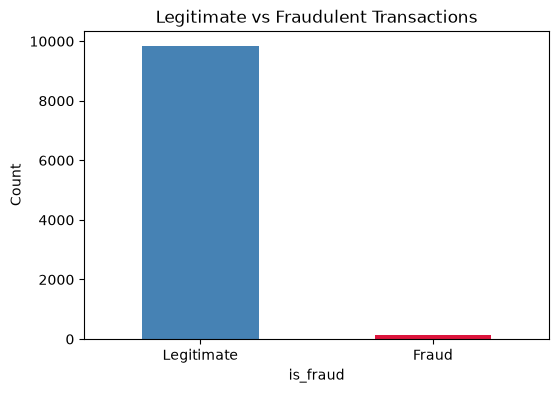

In [4]:
counts = df['is_fraud'].value_counts()
print(counts)
print(f"\nFraud rate: {df['is_fraud'].mean():.2%}")
print(f"Accuracy of a model that always predicts 'not fraud': {1 - df['is_fraud'].mean():.2%}")

counts.rename({0: 'Legitimate', 1: 'Fraud'}).plot(kind='bar', color=['steelblue', 'crimson'], figsize=(6,4))
plt.title('Legitimate vs Fraudulent Transactions')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

Only **151 of 10,000 transactions (1.51%) are fraud**. A model that labels everything "not fraud" would be 98.49% accurate and still catch nothing, so accuracy is useless here. I evaluate models with:

- **Precision:** of the transactions flagged as fraud, how many really are fraud (a measure of false alarms).
- **Recall:** of all real frauds, how many were caught (a measure of missed fraud).
- **F1:** the balance between precision and recall.
- **ROC-AUC:** how well the model ranks fraud above legitimate transactions, regardless of the decision threshold.

## Exploratory Analysis

### Fraud by hour of day

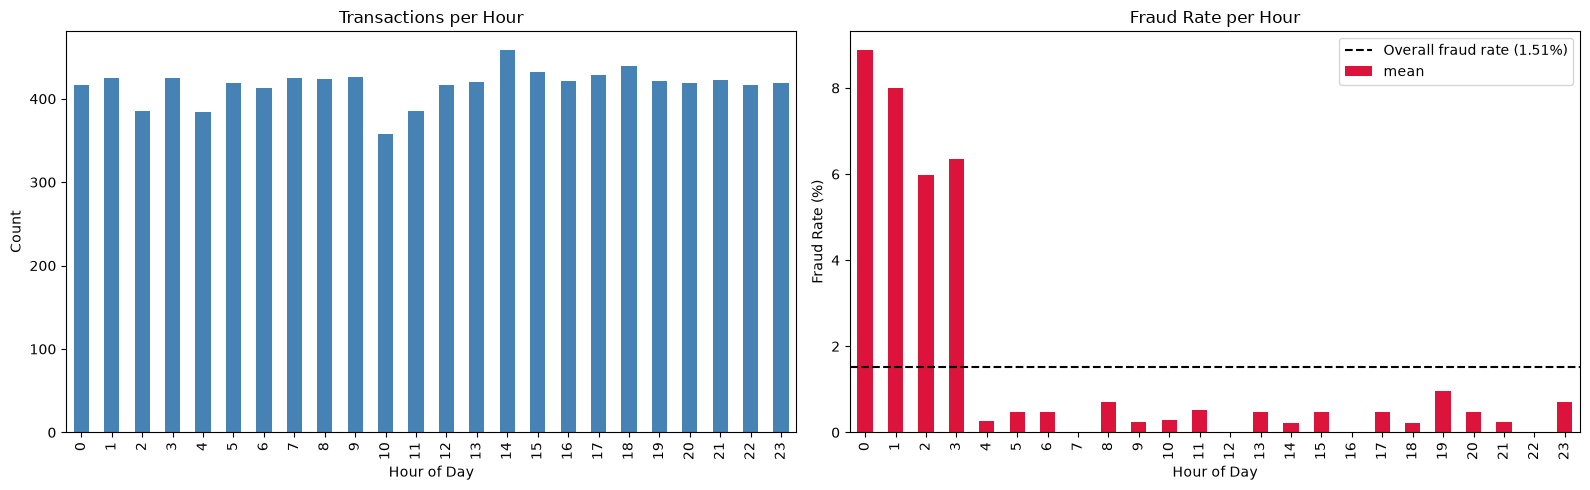

In [5]:
hourly = df.groupby('transaction_hour')['is_fraud'].agg(['size', 'mean'])

fig, axes = plt.subplots(1, 2, figsize=(16,5))
hourly['size'].plot(kind='bar', color='steelblue', ax=axes[0])
axes[0].set_title('Transactions per Hour')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Count')

(hourly['mean'] * 100).plot(kind='bar', color='crimson', ax=axes[1])
axes[1].axhline(df['is_fraud'].mean() * 100, color='black', linestyle='--', label='Overall fraud rate (1.51%)')
axes[1].set_title('Fraud Rate per Hour')
axes[1].set_xlabel('Hour of Day')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].legend()
plt.tight_layout()
plt.show()

In [6]:
night = df['transaction_hour'] <= 3
print(f"Night (00:00-03:59): {night.sum()} transactions ({night.mean():.1%} of all), fraud rate {df.loc[night, 'is_fraud'].mean():.2%}")
print(f"Other hours:         {(~night).sum()} transactions, fraud rate {df.loc[~night, 'is_fraud'].mean():.2%}")
print(f"Share of all fraud happening at night: {df.loc[night, 'is_fraud'].sum()} of {df['is_fraud'].sum()} "
      f"({df.loc[night, 'is_fraud'].sum() / df['is_fraud'].sum():.0%})")

Night (00:00-03:59): 1652 transactions (16.5% of all), fraud rate 7.32%
Other hours:         8348 transactions, fraud rate 0.36%
Share of all fraud happening at night: 121 of 151 (80%)


Time of day is the strongest behavioural signal. Hours 0 to 3 hold only 16.5% of transactions but **80% of all fraud** (121 of 151). The fraud rate is 6 to 9% at night and below 1% during the day.

### Fraud rate by risk factor

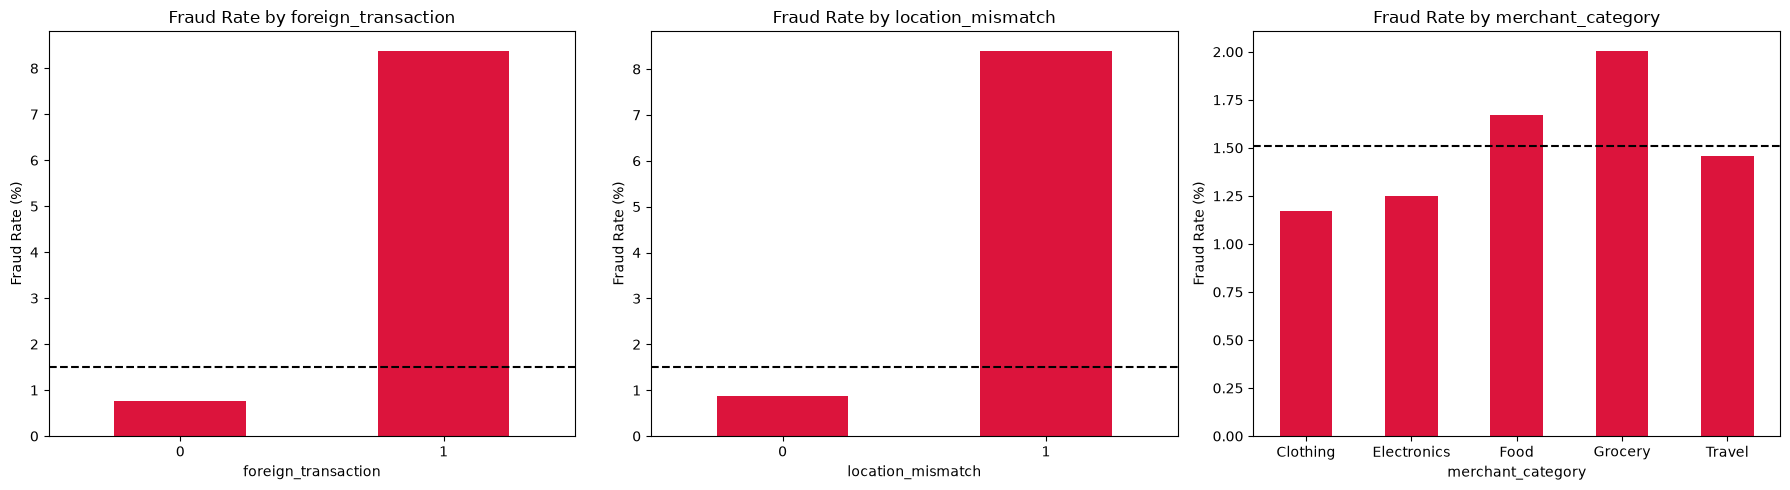

                     transactions  fraud_rate
foreign_transaction                          
0                            9022      0.0076
1                             978      0.0838 

                   transactions  fraud_rate
location_mismatch                          
0                          9143      0.0086
1                           857      0.0840 

                   transactions  fraud_rate
merchant_category                          
Clothing                   2050      0.0117
Electronics                1923      0.0125
Food                       2093      0.0167
Grocery                    1944      0.0201
Travel                     1990      0.0146 



In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, col in zip(axes, ['foreign_transaction', 'location_mismatch', 'merchant_category']):
    rate = df.groupby(col)['is_fraud'].mean() * 100
    rate.plot(kind='bar', color='crimson', ax=ax)
    ax.axhline(df['is_fraud'].mean() * 100, color='black', linestyle='--')
    ax.set_title(f'Fraud Rate by {col}')
    ax.set_ylabel('Fraud Rate (%)')
    ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

for col in ['foreign_transaction', 'location_mismatch', 'merchant_category']:
    print(df.groupby(col)['is_fraud'].agg(transactions='size', fraud_rate='mean').round(4), '\n')

- **Foreign transactions** have an 8.4% fraud rate, about 5.5 times the baseline, compared with 0.76% for domestic ones.
- **Location mismatch** has the same pattern: 8.4% versus 0.86%.
- **Merchant category barely matters.** Every category sits between 1.2% and 2.0%, close to the overall rate.

### Numeric features: fraud vs legitimate

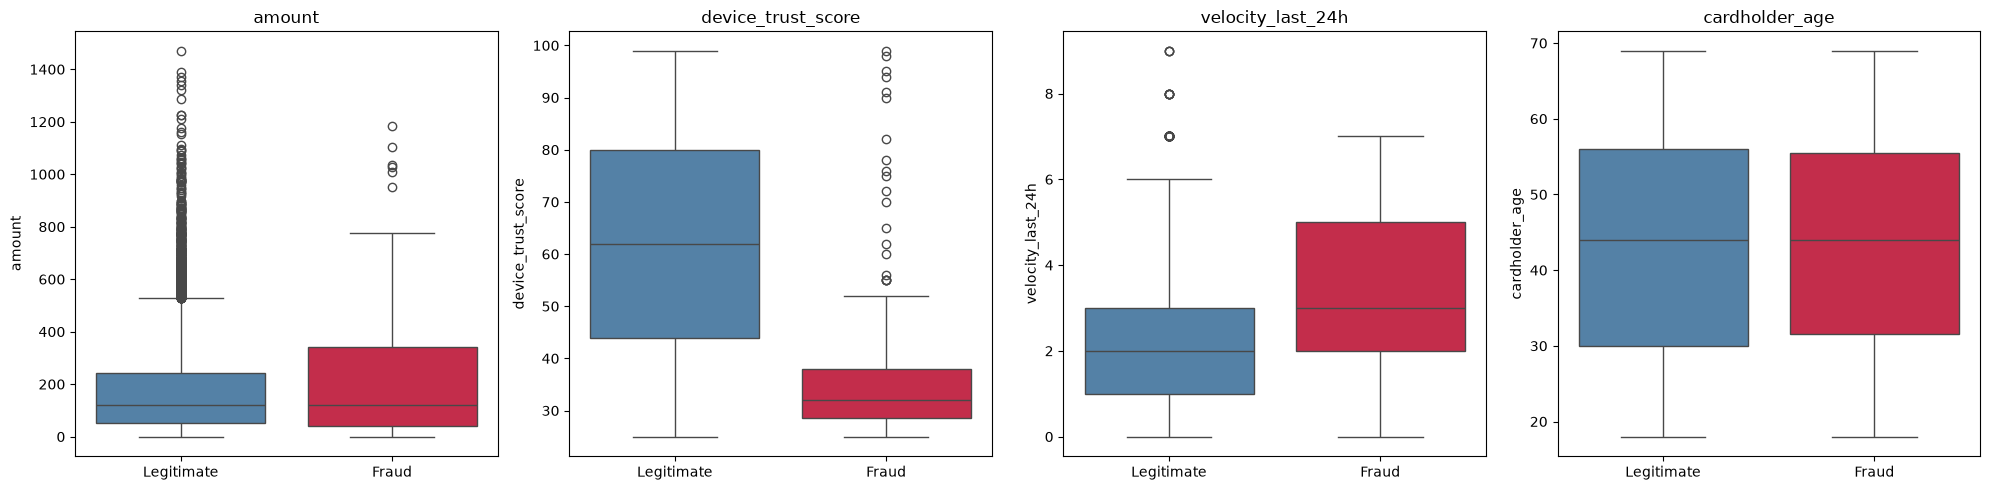

,amount,device_trust_score,velocity_last_24h,cardholder_age
is_fraud,,,,
Legitimate,122.11,62.0,2.0,44.0
Fraud,118.94,32.0,3.0,44.0


In [8]:
num_cols = ['amount', 'device_trust_score', 'velocity_last_24h', 'cardholder_age']

fig, axes = plt.subplots(1, 4, figsize=(20,5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='is_fraud', y=col, hue='is_fraud', palette=['steelblue', 'crimson'], legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Legitimate', 'Fraud'])
    ax.set_xlabel('')
    ax.set_title(col)
plt.tight_layout()
plt.show()

df.groupby('is_fraud')[num_cols].median().rename(index={0: 'Legitimate', 1: 'Fraud'})

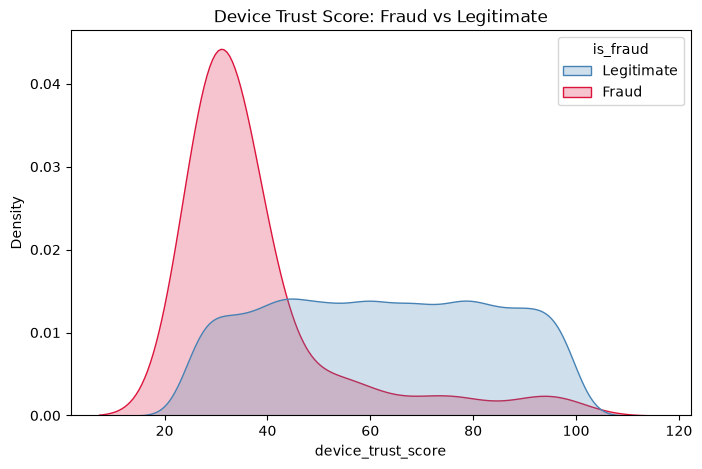

In [9]:
plt.figure(figsize=(8,5))
labels = df['is_fraud'].map({0: 'Legitimate', 1: 'Fraud'})
sns.kdeplot(data=df, x='device_trust_score', hue=labels, common_norm=False, fill=True,
            palette={'Legitimate': 'steelblue', 'Fraud': 'crimson'})
plt.title('Device Trust Score: Fraud vs Legitimate')
plt.show()

- **Device trust score is the strongest numeric separator.** The median for fraud is 32, about half the legitimate median of 62.
- **Velocity is slightly higher for fraud** (median 3 transactions in the last 24 hours versus 2).
- **Amount and cardholder age barely differ.** Fraud is about *how and where* a transaction happens, not how big it is or who the cardholder is.

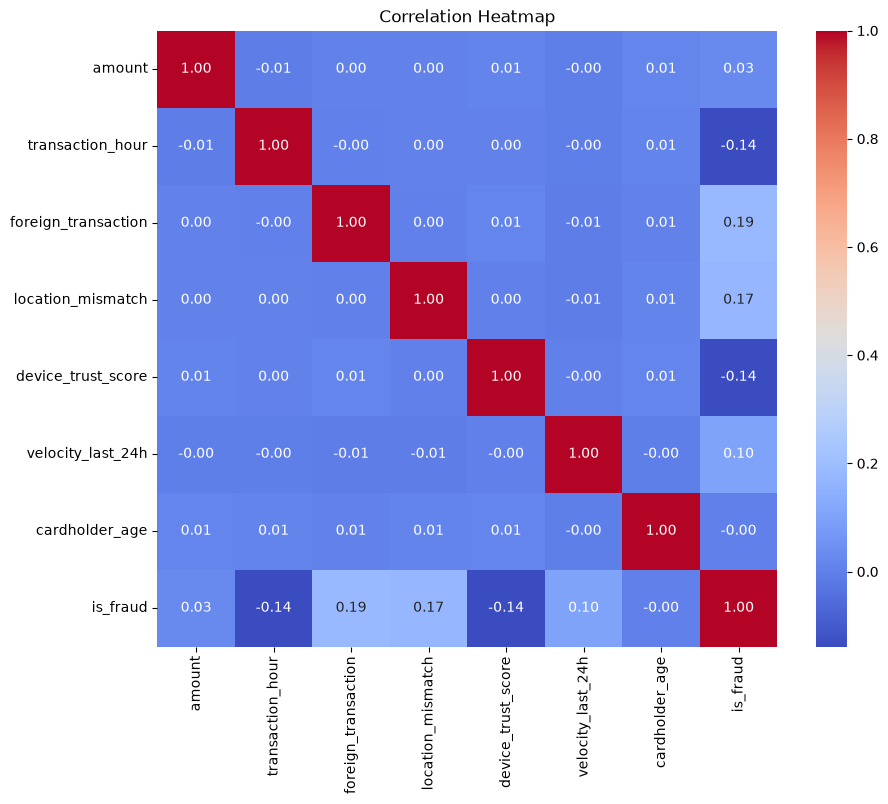

In [10]:
plt.figure(figsize=(10,8))
corr = df.drop(columns=['transaction_id', 'merchant_category']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## Feature Engineering

- **`is_night`:** a flag for hours 0 to 3. Raw hour treats 23:00 and 00:00 as far apart even though they are next to each other on the clock, so a flag captures the night-time window better.
- **One-hot encoded `merchant_category`**, dropping the first category to avoid a redundant column.
- **Dropped `transaction_id`**, since it is just a row label and carries no signal.

In [11]:
df['is_night'] = (df['transaction_hour'] <= 3).astype(int)

X = df.drop(columns=['transaction_id', 'is_fraud'])
X = pd.get_dummies(X, columns=['merchant_category'], drop_first=True, dtype=int)
y = df['is_fraud']

print(X.shape)
X.head()

(10000, 12)


,amount,transaction_hour,foreign_transaction,location_mismatch,device_trust_score,velocity_last_24h,cardholder_age,is_night,merchant_category_Electronics,merchant_category_Food,merchant_category_Grocery,merchant_category_Travel
0,84.47,22,0,0,66,3,40,0,1,0,0,0
1,541.82,3,1,0,87,1,64,1,0,0,0,1
2,237.01,17,0,0,49,1,61,0,0,0,1,0
3,164.33,4,0,1,72,3,34,0,0,0,1,0
4,30.53,15,0,0,79,0,44,0,0,1,0,0


## Train/Test Split, Scaling and SMOTE

- **Stratified 80/20 split**, so the rare fraud class is equally represented in both sets.
- **`StandardScaler` fitted on the training set only**, then applied to the test set.
- **SMOTE applied to the training set only.** It creates synthetic fraud examples so the models see a balanced training set. The test set stays untouched, so no synthetic samples leak into the evaluation.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| frauds:", y_train.sum())
print("Test: ", X_test.shape, "| frauds:", y_test.sum())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)
print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Train: (8000, 12) | frauds: 121
Test:  (2000, 12) | frauds: 30

After SMOTE:
is_fraud
0    7879
1    7879
Name: count, dtype: int64


## Models

I train three models:

1. **Logistic Regression + SMOTE:** a simple, fast, interpretable baseline.
2. **Random Forest + SMOTE:** a non-linear model that can capture interactions such as "night *and* low device trust".
3. **Logistic Regression without SMOTE:** an ablation, to measure what SMOTE actually changes.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)

rf_smote = RandomForestClassifier(random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

lr_plain = LogisticRegression(max_iter=1000, random_state=42)
lr_plain.fit(X_train_scaled, y_train)

models = {
    'Logistic Regression + SMOTE': lr_smote,
    'Random Forest + SMOTE': rf_smote,
    'Logistic Regression (no SMOTE)': lr_plain,
}

## Evaluation

In [14]:
from sklearn.metrics import (classification_report, confusion_matrix, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

results = []
for name, model in models.items():
    pred = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    results.append({
        'Model': name,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
        'Frauds caught (of 30)': tp,
        'False alarms': fp,
    })
    print(f"--- {name} ---")
    print(classification_report(y_test, pred, target_names=['Legitimate', 'Fraud'], digits=3))

results = pd.DataFrame(results).set_index('Model').round(3)
results

--- Logistic Regression + SMOTE ---
              precision    recall  f1-score   support

  Legitimate      1.000     0.982     0.991      1970
       Fraud      0.455     1.000     0.625        30

    accuracy                          0.982      2000
   macro avg      0.727     0.991     0.808      2000
weighted avg      0.992     0.982     0.985      2000

--- Random Forest + SMOTE ---
              precision    recall  f1-score   support

  Legitimate      0.996     1.000     0.998      1970
       Fraud      1.000     0.733     0.846        30

    accuracy                          0.996      2000
   macro avg      0.998     0.867     0.922      2000
weighted avg      0.996     0.996     0.996      2000

--- Logistic Regression (no SMOTE) ---
              precision    recall  f1-score   support

  Legitimate      0.997     0.996     0.997      1970
       Fraud      0.781     0.833     0.806        30

    accuracy                          0.994      2000
   macro avg      0.889

,Precision,Recall,F1,ROC-AUC,Frauds caught (of 30),False alarms
Model,,,,,,
Logistic Regression + SMOTE,0.455,1.000,0.625,0.998,30,36
Random Forest + SMOTE,1.000,0.733,0.846,1.000,22,0
Logistic Regression (no SMOTE),0.781,0.833,0.806,0.998,25,7


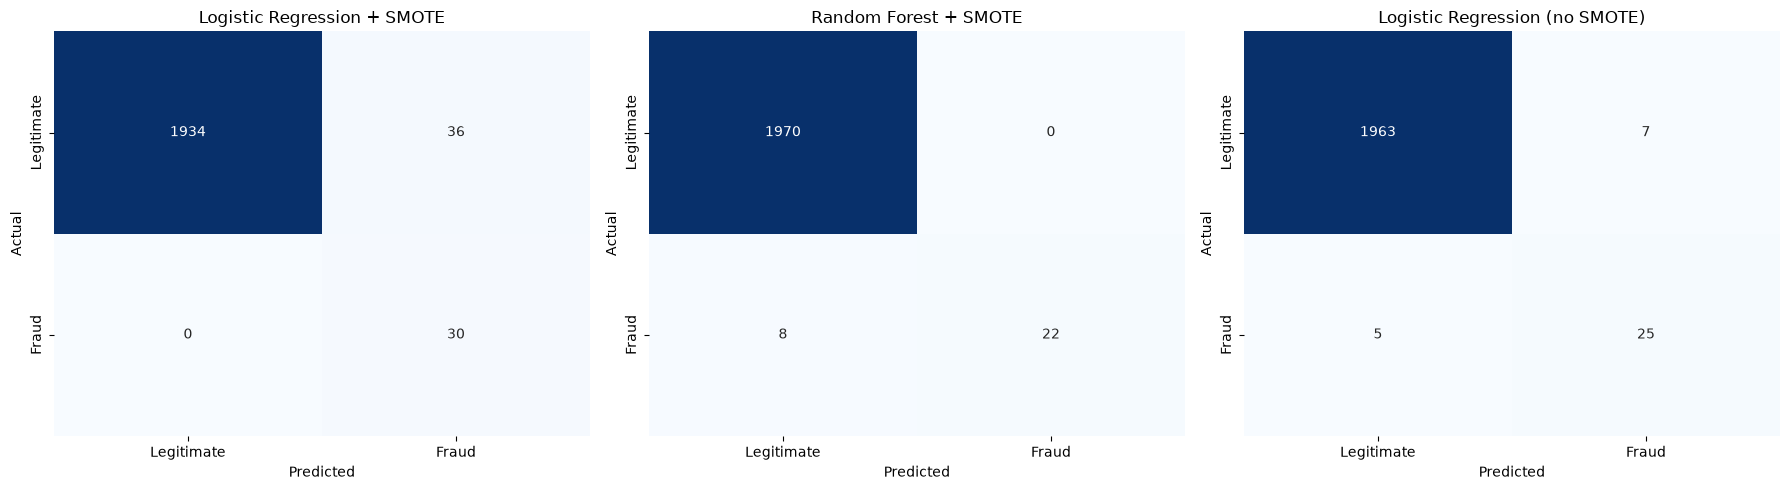

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18,5))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_scaled))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Legitimate', 'Fraud'], yticklabels=['Legitimate', 'Fraud'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

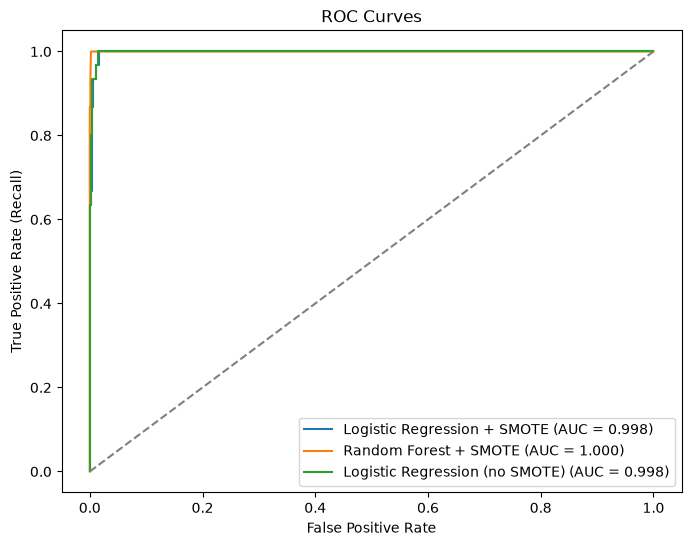

In [16]:
plt.figure(figsize=(8,6))
for name, model in models.items():
    proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()
plt.show()

- **Logistic Regression + SMOTE caught all 30 test frauds**, at the cost of 36 false alarms (1.8% of legitimate transactions).
- **Random Forest + SMOTE raised zero false alarms** but missed 8 frauds.
- **SMOTE is a trade-off, not a free improvement.** On Logistic Regression it raised recall from 0.83 to 1.00 but cut precision from 0.78 to 0.46, so F1 actually fell from 0.81 to 0.63.
- **All models rank transactions almost perfectly (AUC close to 1.0).** The difference between them comes from where the default 0.5 threshold sits, so tuning the threshold is the main remaining lever.
- **The test sample is small.** With only 30 test frauds, each fraud moves recall by about 3.3 points, so the differences between models are noisy.

## Feature Importance

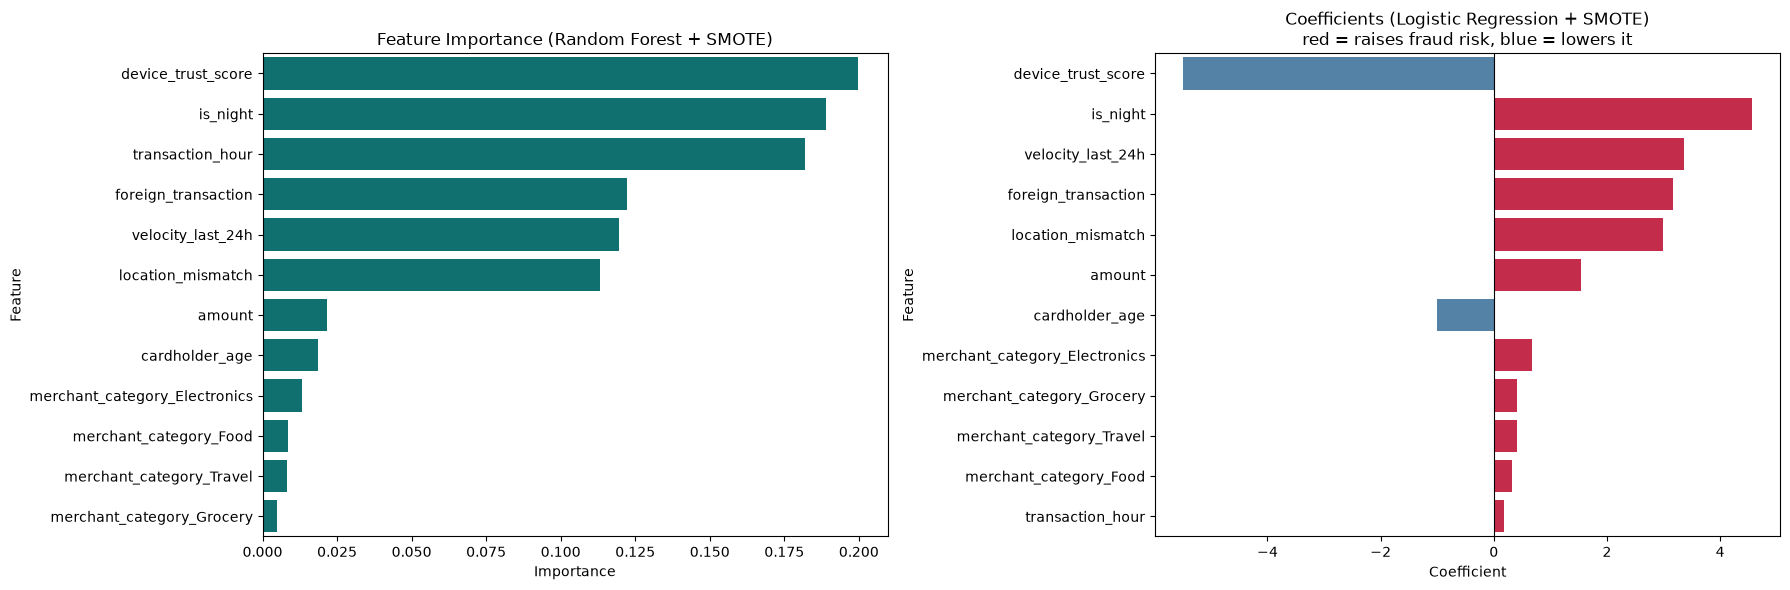

In [17]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_smote.feature_importances_
}).sort_values(by='Importance', ascending=False)

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_smote.coef_[0]
}).sort_values(by='Coefficient', key=abs, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18,6))
sns.barplot(data=importance, x='Importance', y='Feature', color='teal', ax=axes[0])
axes[0].set_title('Feature Importance (Random Forest + SMOTE)')

colors = ['crimson' if c > 0 else 'steelblue' for c in coefficients['Coefficient']]
sns.barplot(data=coefficients, x='Coefficient', y='Feature', hue='Feature', palette=colors, legend=False, ax=axes[1])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Coefficients (Logistic Regression + SMOTE)\nred = raises fraud risk, blue = lowers it')
plt.tight_layout()
plt.show()

Both models agree with the exploratory analysis. **Device trust score** (low trust means fraud) and **is_night** are the top predictors, followed by velocity in the last 24 hours, foreign transaction and location mismatch. The Random Forest also ranks raw `transaction_hour` highly, because it carries the same night-time signal as `is_night`. Amount, cardholder age and merchant category contribute very little.

## Recommendation: Choose by Cost

There is no single "best" model. The right choice depends on what a missed fraud costs the business compared with a false alarm.

| If the business priority is... | Use | Why |
|---|---|---|
| **Catching every fraud** (high loss per fraud, analysts available) | **LR + SMOTE** | 100% recall, and 36 alerts per 2,000 transactions (1.8%) is a workload a review team can handle |
| **Never blocking good customers** (limited review capacity) | **Random Forest + SMOTE** | Zero false positives, but about 1 in 4 frauds gets through |
| **A balance of both** | Random Forest with a **lower decision threshold** | AUC close to 1.0 means recall can probably be raised with few extra false alarms |

As immediate rule-based safeguards, **step-up authentication (for example an OTP) for night-time, foreign or location-mismatch transactions from low-trust devices** would target the highest-risk segments found in the analysis.

## Scalability: 1 Million Transactions per Hour

- 1 million transactions per hour is about **280 per second**. Scoring one transaction with Logistic Regression or a moderately sized Random Forest takes milliseconds.
- **Training, including SMOTE, runs offline.** Only the lightweight predict step runs on live traffic. That step is stateless, so it scales horizontally across instances.
- Logistic Regression is the cheapest to serve. A large Random Forest needs more memory and CPU per prediction.
- Fraud patterns drift over time, so the system needs **monitoring of precision and recall, alerts on drift, and scheduled retraining**.

## Limitations

- **The data is probably synthetic.** The near-perfect separation (AUC close to 1.0) and the very clean night and foreign patterns are unusually tidy. Expect noticeably lower performance on real transactions.
- **There are few positive cases:** 151 frauds in total and 30 in the test set. Stratified cross-validation would give more reliable estimates.
- **Default thresholds and hyperparameters were used.** Precision-recall curve analysis and threshold tuning are the natural next steps.
- **There is no cost-weighted evaluation yet.** Adding the average fraud loss and the cost of a review would allow a direct choice of the cheapest threshold.